In [1]:
from google.colab import files
uploaded = files.upload()

Saving sales_eda_dataset_50_records.xlsx to sales_eda_dataset_50_records.xlsx


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_excel("sales_eda_dataset_50_records.xlsx")

df.head()

,OrderID,Date,Region,Product,Units,UnitPrice,DiscountPct,Channel,Revenue
0,1001,2026-01-05,North,Laptop,1,1000,0.05,Online,950.0
1,1002,2026-01-12,South,Mouse,4,25,0.60,Store,40.0
2,1003,2026-01-18,East,Laptop,1,1000,0.10,Store,900.0
3,1004,2026-02-01,North,Keyboard,5,75,0.10,Online,337.5
4,1005,2026-02-14,South,Laptop,2,1000,0.00,Store,2000.0


In [6]:
#calculate revenue

df["Date"] = pd.to_datetime(df["Date"])

df["Revenue"] = (
    df["Units"]
    * df["UnitPrice"]
    * (1 - df["DiscountPct"])
)

df


,OrderID,Date,Region,Product,Units,UnitPrice,DiscountPct,Channel,Revenue
0,1001,2026-01-05,North,Laptop,1,1000,0.05,Online,950.00
1,1002,2026-01-12,South,Mouse,4,25,0.60,Store,40.00
2,1003,2026-01-18,East,Laptop,1,1000,0.10,Store,900.00
3,1004,2026-02-01,North,Keyboard,5,75,0.10,Online,337.50
4,1005,2026-02-14,South,Laptop,2,1000,0.00,Store,2000.00
5,1006,2026-02-20,East,Keyboard,1,75,0.05,Online,71.25
6,1007,2026-03-02,North,Laptop,3,1000,0.00,Store,3000.00
7,1008,2026-03-15,South,Mouse,6,25,0.15,Online,127.50
8,1009,2026-03-29,East,Laptop,1,1000,0.00,Store,1000.00
9,1010,2026-04-03,North,Laptop,1,1000,0.10,Online,900.00


In [7]:
# Data inspections

# Display the first five rows
df.head()

# Dataset structure and data types
df.info()

# Number of rows and columns
print("Shape:", df.shape)

# Missing values in each column
print(df.isnull().sum())

# Number of duplicate rows
print("Duplicate records:", df.duplicated().sum())

# Descriptive statistics
df.describe()

# Mean revenue
print("Mean Revenue:", df["Revenue"].mean())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   OrderID      50 non-null     int64         
 1   Date         50 non-null     datetime64[ns]
 2   Region       50 non-null     object        
 3   Product      50 non-null     object        
 4   Units        50 non-null     int64         
 5   UnitPrice    50 non-null     int64         
 6   DiscountPct  50 non-null     float64       
 7   Channel      50 non-null     object        
 8   Revenue      50 non-null     float64       
dtypes: datetime64[ns](1), float64(2), int64(3), object(3)
memory usage: 3.6+ KB
Shape: (50, 9)
OrderID        0
Date           0
Region         0
Product        0
Units          0
UnitPrice      0
DiscountPct    0
Channel        0
Revenue        0
dtype: int64
Duplicate records: 0
Mean Revenue: 1258.525


In [8]:
#Count product occurrences using value_counts()

product_counts = df["Product"].value_counts()
print(product_counts)


Product
Laptop      25
Keyboard    13
Mouse       12
Name: count, dtype: int64


In [9]:
#Calculate total units and revenue by product

product_summary = (
    df.groupby("Product")
    .agg(
        TotalRevenue=("Revenue", "sum"),
        UnitsSold=("Units", "sum"),
        Orders=("OrderID", "count")
    )
    .sort_values("TotalRevenue", ascending=False)
)

product_summary


,TotalRevenue,UnitsSold,Orders
Product,,,
Laptop,59650.00,64,25
Keyboard,2328.75,34,13
Mouse,947.50,43,12


In [10]:
#Average revenue per product order

product_summary["AverageRevenuePerOrder"] = (
    df.groupby("Product")["Revenue"].mean()
)

product_summary


,TotalRevenue,UnitsSold,Orders,AverageRevenuePerOrder
Product,,,,
Laptop,59650.00,64,25,2386.000000
Keyboard,2328.75,34,13,179.134615
Mouse,947.50,43,12,78.958333


In [11]:
#Regional revenue analysis

region_summary = (
    df.groupby("Region")
    .agg(
        TotalRevenue=("Revenue", "sum"),
        AverageOrderRevenue=("Revenue", "mean"),
        OrderCount=("OrderID", "count")
    )
    .sort_values("TotalRevenue", ascending=False)
)

region_summary


,TotalRevenue,AverageOrderRevenue,OrderCount
Region,,,
North,22462.50,1182.236842,19
East,19926.25,1660.520833,12
West,12417.50,1552.187500,8
South,8120.00,738.181818,11


In [12]:
#Regional sales channel comparison

channel_summary = (
    df.groupby(["Region", "Channel"])
    .agg(
        TotalRevenue=("Revenue", "sum"),
        UnitsSold=("Units", "sum"),
        OrderCount=("OrderID", "count")
    )
    .sort_values("TotalRevenue", ascending=False)
)

channel_summary


TotalRevenue  UnitsSold  OrderCount
Region Channel                                     
East   Online       14677.50         25           6
North  Online       12250.00         30          13
       Store        10212.50         17           6
West   Online        6248.75         16           5
       Store         6168.75         12           3
East   Store         5248.75         16           6
South  Store         4103.75          9           4
       Online        4016.25         16           7

In [13]:
#Generate the correlation matrix

correlation_matrix = df[
    ["Units", "UnitPrice", "DiscountPct", "Revenue"]
].corr()

correlation_matrix


,Units,UnitPrice,DiscountPct,Revenue
Units,1.000000,-0.166867,-0.001007,0.362156
UnitPrice,-0.166867,1.000000,-0.148766,0.731213
DiscountPct,-0.001007,-0.148766,1.000000,-0.195795
Revenue,0.362156,0.731213,-0.195795,1.000000


In [14]:
#Correlation between units and revenue

units_revenue_correlation = (
    df["Units"].corr(df["Revenue"])
)

print(
    "Correlation between units and revenue:",
    units_revenue_correlation
)


Correlation between units and revenue: 0.36215619844523506


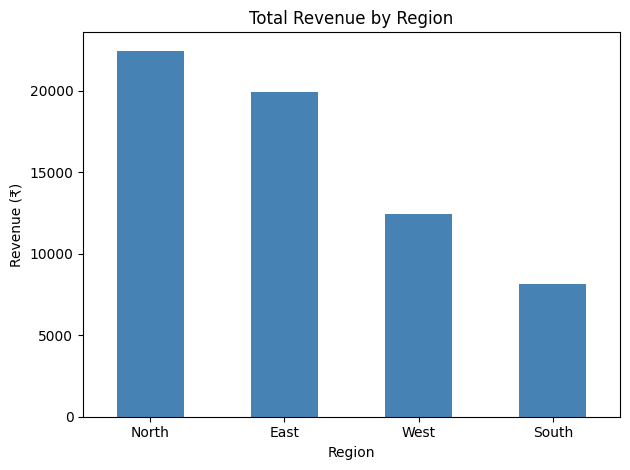

In [15]:
#Bar chart — total revenue by region

region_summary["TotalRevenue"].plot(
    kind="bar",
    color="steelblue",
    title="Total Revenue by Region"
)

plt.xlabel("Region")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [17]:
#Line chart — monthly revenue trend

df["Month"] = df["Date"].dt.to_period("M")

monthly_summary = (
    df.groupby("Month")
    .agg(
        TotalRevenue=("Revenue", "sum"),
        Orders=("OrderID", "count")
    )
    .sort_index()
)

monthly_summary


,TotalRevenue,Orders
Month,,
2026-01,15125.00,10
2026-02,13172.50,10
2026-03,13910.00,9
2026-04,6325.00,9
2026-05,7887.50,6
2026-06,6506.25,6


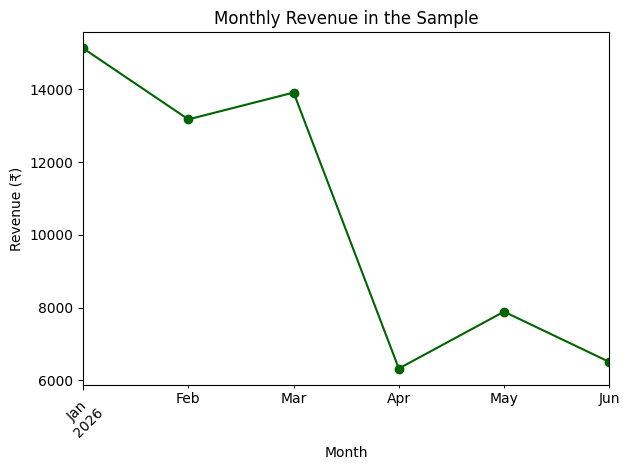

In [18]:

monthly_summary["TotalRevenue"].plot(
    kind="line",
    marker="o",
    color="darkgreen",
    title="Monthly Revenue in the Sample"
)

plt.xlabel("Month")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


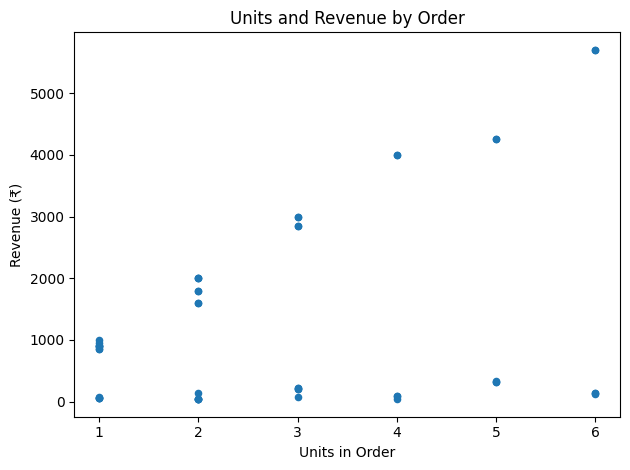

In [19]:
#Scatter plot — units versus revenue

df.plot(
    kind="scatter",
    x="Units",
    y="Revenue",
    title="Units and Revenue by Order"
)

plt.xlabel("Units in Order")
plt.ylabel("Revenue (₹)")
plt.tight_layout()
plt.show()


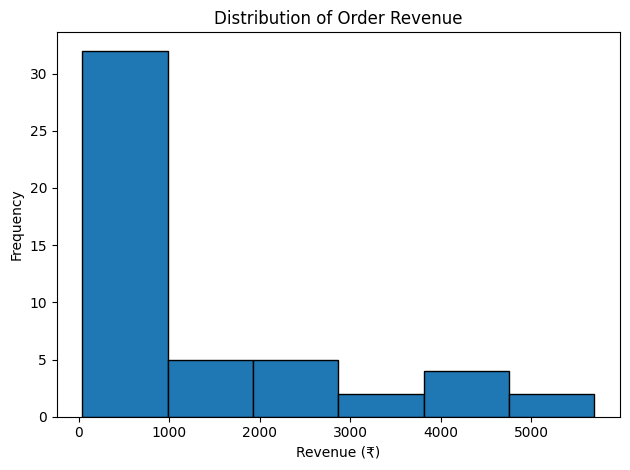

In [20]:
#Histogram — distribution of revenue

df["Revenue"].plot(
    kind="hist",
    bins=6,
    edgecolor="black",
    title="Distribution of Order Revenue"
)

plt.xlabel("Revenue (₹)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


In [21]:
#Top five highest-revenue orders

top_orders = df.sort_values(
    "Revenue",
    ascending=False
)[
    [
        "OrderID",
        "Date",
        "Region",
        "Product",
        "Units",
        "UnitPrice",
        "DiscountPct",
        "Channel",
        "Revenue"
    ]
].head(5)

top_orders


,OrderID,Date,Region,Product,Units,UnitPrice,DiscountPct,Channel,Revenue
44,1045,2026-03-02,East,Laptop,6,1000,0.05,Online,5700.0
24,1025,2026-01-10,East,Laptop,6,1000,0.05,Online,5700.0
23,1024,2026-06-05,West,Laptop,5,1000,0.15,Online,4250.0
43,1044,2026-02-24,West,Laptop,5,1000,0.15,Store,4250.0
16,1017,2026-05-24,North,Laptop,4,1000,0.00,Store,4000.0


In [22]:
#Monthly revenue by region

monthly_region = (
    df.groupby(["Month", "Region"])
    .agg(
        TotalRevenue=("Revenue", "sum"),
        OrderCount=("OrderID", "count")
    )
    .reset_index()
)

monthly_region


,Month,Region,TotalRevenue,OrderCount
0,2026-01,East,6600.00,2
1,2026-01,North,6795.00,4
2,2026-01,South,90.00,2
3,2026-01,West,1640.00,2
4,2026-02,East,3135.00,3
5,2026-02,North,3405.00,3
6,2026-02,South,2063.75,2
7,2026-02,West,4568.75,2
8,2026-03,East,6842.50,3
9,2026-03,North,4900.00,3


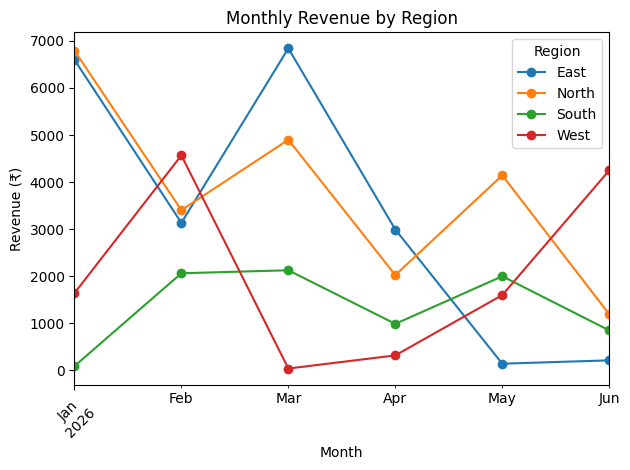

In [23]:

monthly_region_pivot = monthly_region.pivot(
    index="Month",
    columns="Region",
    values="TotalRevenue"
)

monthly_region_pivot.plot(
    kind="line",
    marker="o",
    title="Monthly Revenue by Region"
)

plt.xlabel("Month")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=45)
plt.legend(title="Region")
plt.tight_layout()
plt.show()


In [24]:
#Discount analysis

discount_summary = (
    df.groupby("DiscountPct")
    .agg(
        TotalRevenue=("Revenue", "sum"),
        AverageRevenue=("Revenue", "mean"),
        OrderCount=("OrderID", "count")
    )
    .sort_values("DiscountPct")
)

discount_summary


,TotalRevenue,AverageRevenue,OrderCount
DiscountPct,,,
0.00,21775.00,1555.357143,14
0.05,18976.25,1725.113636,11
0.10,7762.50,705.681818,11
0.15,11092.50,1232.500000,9
0.20,3280.00,820.000000,4
0.60,40.00,40.000000,1


In [25]:
#Compare Online and Store performance

channel_comparison = (
    df.groupby("Channel")
    .agg(
        TotalRevenue=("Revenue", "sum"),
        AverageRevenue=("Revenue", "mean"),
        UnitsSold=("Units", "sum"),
        OrderCount=("OrderID", "count")
    )
    .sort_values("TotalRevenue", ascending=False)
)

channel_comparison


,TotalRevenue,AverageRevenue,UnitsSold,OrderCount
Channel,,,,
Online,37192.50,1199.758065,87,31
Store,25733.75,1354.407895,54,19


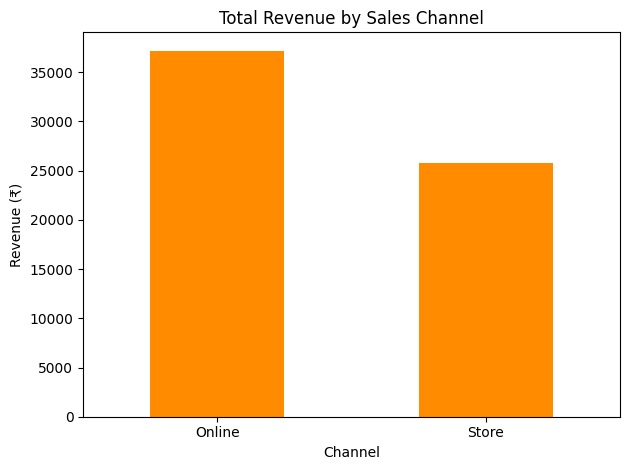

In [26]:

channel_comparison["TotalRevenue"].plot(
    kind="bar",
    color="darkorange",
    title="Total Revenue by Sales Channel"
)

plt.xlabel("Channel")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [28]:
#weekday performance

df["DayOfWeek"] = df["Date"].dt.day_name()

weekday_summary = (
    df.groupby("DayOfWeek")
    .agg(
        TotalRevenue=("Revenue", "sum"),
        OrderCount=("OrderID", "count"),
        AverageRevenue=("Revenue", "mean")
    )
    .sort_values("TotalRevenue", ascending=False)
)

weekday_summary


,TotalRevenue,OrderCount,AverageRevenue
DayOfWeek,,,
Saturday,13660.00,7,1951.428571
Monday,12067.50,8,1508.437500
Sunday,10903.75,10,1090.375000
Friday,9535.00,6,1589.166667
Tuesday,6531.25,6,1088.541667
Thursday,5482.50,5,1096.500000
Wednesday,4746.25,8,593.281250
